# Pandas Assignment: Bengaluru Real Estate

**Case study:** *Which Bengaluru localities are overpriced?*

| | |
|---|---|
| **Name** |Ritesh Banajgolkar|
| **Roll No.** | SCLU326037|
| **Total marks** | 10 (Assignment 5 + Viva 5) |
| **Dataset** | `Bengaluru_House_Data.csv` (put it in the same folder as this notebook) |

## Scenario
You have joined a real-estate analytics startup. The team gives you a raw listing file scraped from the web and asks you to clean it, explore it, and prepare it for a price-prediction model. Your manager also wants a short list of insights.

## Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `area_type` | Type of area (e.g. Super built-up Area, Plot Area) | Categorical |
| `availability` | Ready to move, or a possession date | Categorical |
| `location` | Locality in Bengaluru | Categorical |
| `size` | Number of bedrooms, written as text (e.g. "2 BHK") | Categorical (text) |
| `society` | Society / project name | Categorical |
| `total_sqft` | Area in square feet (may be messy) | Numerical (stored as text) |
| `bath` | Number of bathrooms | Numerical |
| `balcony` | Number of balconies | Numerical |
| `price` | Price in **lakhs** of rupees | Numerical |

## Rules
1. Use only `pandas`, `numpy` and `matplotlib`. Write scaling formulas yourself (no scikit-learn).
2. Never edit the CSV by hand. All cleaning must be done in code.
3. Work on a copy: keep `raw = pd.read_csv(...)` untouched and clean `df = raw.copy()`.
4. **Every cleaning decision needs a one-line reason** in the answer cell. Code without reasoning gets half marks.
5. Run the notebook from top to bottom (Kernel > Restart and Run All) before submitting.
6. Submit the `.ipynb` file named `RollNo_Name_Bengaluru.ipynb`.

## Marks split

| Component | Marks |
|---|---|
| Assignment (this notebook) | 5 |
| Viva (based on your own notebook) | 5 |
| **Total** | **10** |

The assignment is marked on the whole notebook: correct code, visible output and a written reason for every cleaning decision.

## Setup

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv('Bengaluru_House_Data.csv')
df = raw.copy()
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


---
## Part A: Understand the data

**A1.** Print the shape, the data type of every column, and a summary that includes both numerical and categorical columns.

In [6]:
print(df.shape)
print(df.dtypes)
print(df.describe(include='all'))


(13320, 9)
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object
                   area_type   availability    location   size  society  \
count                  13320          13320       13319  13304     7818   
unique                     4             81        1305     31     2688   
top     Super built-up  Area  Ready To Move  Whitefield  2 BHK  GrrvaGr   
freq                    8790          10581         540   5199       80   
mean                     NaN            NaN         NaN    NaN      NaN   
std                      NaN            NaN         NaN    NaN      NaN   
min                      NaN            NaN         NaN    NaN      NaN   
25%                      NaN            NaN         NaN    NaN      NaN   
50%                      NaN            NaN         NaN    NaN      NaN   
75%      

**A2.** List which columns are numerical and which are categorical *as they are stored right now*. One column is numerical in meaning but stored as text. Name it.

**Your answer / justification:**

It looks like a number, like 1056, 2600, but it is actually stored as text.

---
## Part B: Data quality audit

**B1.** Show the number **and percentage** of missing values in each column, sorted from highest to lowest.

In [7]:
# YOUR CODE HERE
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent': df.isnull().mean() * 100
})
missing.sort_values('Missing_Percent', ascending=False)


,Missing_Count,Missing_Percent
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


**B2.** How many rows are exact duplicates? Show a few of them.

In [8]:
# YOUR CODE HERE
print(df.duplicated().sum())
print(df[df.duplicated(keep=False)].head())

529
               area_type   availability               location   size  \
8   Super built-up  Area  Ready To Move           Marathahalli  3 BHK   
33  Super built-up  Area  Ready To Move  Raja Rajeshwari Nagar  3 BHK   
35  Super built-up  Area         21-Dec         Kanakpura Road  2 BHK   
38  Super built-up  Area  Ready To Move         Chikkalasandra  3 BHK   
55  Super built-up  Area  Ready To Move             Begur Road  2 BHK   

    society total_sqft  bath  balcony  price  
8       NaN       1310   3.0      1.0  63.25  
33  GrrvaGr       1693   3.0      3.0  57.39  
35  PrarePa        700   2.0      1.0  36.00  
38      NaN       1290   2.0      2.0  56.12  
55  Dhalsh        1200   2.0      2.0  44.00  


**B3.** Write a short audit report (3 to 5 lines): which columns have the biggest problems and what you plan to do about each.

**Your answer / justification:**

society is the biggest problem - 41.31% missing.
balcony has 4.57% missing.
bath, size, location have very tiny missing values (<1%).
529 exact duplicate rows (3.97%)
total_sqft has 0 missing, but it is stored as text and has ranges. 

---
## Part C: Cleaning

**C1.** Remove duplicate rows. Print the shape before and after.

In [9]:
# YOUR CODE HERE
print("Before:", df.shape)
df = df.drop_duplicates()
print("After:", df.shape)


Before: (13320, 9)
After: (12791, 9)


**C2.** One column has so many missing values that filling it would be unreliable. Identify it, drop it, and justify.

In [10]:
# YOUR CODE HERE
df = df.drop(columns=['society'], errors='ignore')

**Your answer / justification:**

society
society has 5,502 missing values = 41.31%

**C3.** Handle the remaining missing values in `location`, `size`, `bath` and `balcony`.
For **each** column, choose drop, fill with a constant, or fill with mean/median/mode, and justify.

*Hint: think about which columns are categorical and which are numerical, and about how many rows each choice would affect.*

In [11]:
# YOUR CODE HERE
df = df.dropna(subset=['location'])
df['size'] = df['size'].fillna(df['size'].mode()[0])
df['bath'] = df['bath'].fillna(df['bath'].median())
df['balcony'] = df['balcony'].fillna(df['balcony'].median())


**Your answer / justification:**

_(write here)_

**C4.** The `location` column has inconsistent text (extra spaces, different capitalisation). Clean it and show how many unique locations you had before and after.

In [12]:
# YOUR CODE HERE
print("Before cleaning:", df['location'].nunique())

df['location'] = df['location'].str.strip()  # remove extra space start/end
df['location'] = df['location'].str.replace(r'\s+', ' ', regex=True)  # double space -> single space
df['location'] = df['location'].str.title()  # same capitalisation: Anand Nagar

print("After cleaning:", df['location'].nunique())


Before cleaning: 1305
After cleaning: 1282


---
## Part D: Fix messy columns

**D1.** `size` is text such as `"2 BHK"` or `"4 Bedroom"`. Create a new integer column `bhk` from it.

*Hint: `str.split` or `apply` with a lambda.*

In [13]:
# YOUR CODE HERE
df['bhk'] = df['size'].str.split().str[0].astype(int)

**D2.** `total_sqft` is stored as text. Some entries are ranges (e.g. `"1200 - 1400"`) and a few contain other units.
Write a function `to_sqft(x)` that returns a single float: the average for a range, the number itself for a plain value, and `NaN` when it cannot be converted. Apply it, then decide what to do with the rows that became `NaN`.

In [14]:
def to_sqft(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip()

    if '-' in x:
        try:
            parts = x.split('-')
            return (float(parts[0]) + float(parts[1])) / 2
        except:
            return np.nan

    try:
        return float(x)
    except:
        return np.nan
# df['total_sqft'] = df['total_sqft'].apply(to_sqft)


**Your answer / justification:**

i converted normal values into floats and ranges into their average. Invalid values were changed to NaN, and those rows were removed because property area is important for analysis.

**D3.** Confirm that `bhk` and `total_sqft` are now numeric by printing `df.dtypes`. Convert `bath` and `bhk` to a smaller integer type if possible, and show the memory saved.

In [15]:
# YOUR CODE HERE
print(df.dtypes)
memory_before = df[['bath', 'bhk']].memory_usage(deep=True).sum()

print("Memory before conversion:", memory_before, "bytes")
df['bath'] = df['bath'].astype('Int8')
df['bhk'] = df['bhk'].astype('Int8')
memory_after = df[['bath', 'bhk']].memory_usage(deep=True).sum()

print("Memory before:", memory_before, "bytes")
print("Memory after:", memory_after, "bytes")
print("Memory saved:", memory_before - memory_after, "bytes")

print("\nUpdated Data Types:")
print(df.dtypes)

area_type        object
availability     object
location         object
size             object
total_sqft       object
bath            float64
balcony         float64
price           float64
bhk               int64
dtype: object
Memory before conversion: 306960 bytes
Memory before: 306960 bytes
Memory after: 153480 bytes
Memory saved: 153480 bytes

Updated Data Types:
area_type        object
availability     object
location         object
size             object
total_sqft       object
bath               Int8
balcony         float64
price           float64
bhk                Int8
dtype: object


---
## Part E: New columns

**E1.** Price is in lakhs. Create `price_per_sqft` in **rupees per square foot** (1 lakh = 100,000 rupees).

In [16]:
# YOUR CODE HERE
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['total_sqft'] = pd.to_numeric(df['total_sqft'], errors='coerce')
df['price_per_sqft'] = (df['price'] * 100000) / df['total_sqft']
print(df[['price', 'total_sqft', 'price_per_sqft']].head())
print(df.columns)
print(df.dtypes)
print(df.isnull().sum())


    price  total_sqft  price_per_sqft
0   39.07      1056.0     3699.810606
1  120.00      2600.0     4615.384615
2   62.00      1440.0     4305.555556
3   95.00      1521.0     6245.890861
4   51.00      1200.0     4250.000000
Index(['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath',
       'balcony', 'price', 'bhk', 'price_per_sqft'],
      dtype='object')
area_type          object
availability       object
location           object
size               object
total_sqft        float64
bath                 Int8
balcony           float64
price             float64
bhk                  Int8
price_per_sqft    float64
dtype: object
area_type           0
availability        0
location            0
size                0
total_sqft        246
bath                0
balcony             0
price               0
bhk                 0
price_per_sqft    246
dtype: int64


**E2.** Create `sqft_per_bhk` (area divided by number of bedrooms).

In [17]:
# YOUR CODE HERE
df['total_sqft'] = pd.to_numeric(df['total_sqft'], errors='coerce')
df['bhk'] = pd.to_numeric(df['bhk'], errors='coerce')
df['sqft_per_bhk'] = df['total_sqft'] / df['bhk'].replace(0, np.nan)
print(df[['total_sqft', 'bhk', 'sqft_per_bhk']].head())


   total_sqft  bhk  sqft_per_bhk
0      1056.0    2         528.0
1      2600.0    4         650.0
2      1440.0    3         480.0
3      1521.0    3         507.0
4      1200.0    2         600.0


**E3.** Create a categorical column `price_band` with three labels (`Budget`, `Mid`, `Premium`) based on `price`. Choose the cut points yourself, justify them, and show the count of each band.

In [18]:
# YOUR CODE HERE
bins = [0, 50, 100, float('inf')]

labels = ['Budget', 'Mid', 'Premium']

df['price_band'] = pd.cut(df['price'], bins=bins, labels=labels)
print(df[['price', 'price_band']].head())
print(df['price_band'].value_counts())
print(df['price_band'].value_counts().reindex(labels, fill_value=0))

    price price_band
0   39.07     Budget
1  120.00    Premium
2   62.00        Mid
3   95.00        Mid
4   51.00        Mid
price_band
Mid        5477
Premium    4014
Budget     3299
Name: count, dtype: int64
price_band
Budget     3299
Mid        5477
Premium    4014
Name: count, dtype: int64


**Your answer / justification:**

_(write here)_

---
## Part F: Selection and filtering

Answer each query with one line of Pandas. Show the result and the number of rows.

**F1.** All flats with 3 BHK and price under 100 lakhs.

In [19]:
# YOUR CODE HERE
result = df[(df['bhk'] == 3) & (df['price'] < 100)]
print(result)
print("Number of rows:", len(result))


                  area_type   availability            location   size  \
2            Built-up  Area  Ready To Move         Uttarahalli  3 BHK   
3      Super built-up  Area  Ready To Move  Lingadheeranahalli  3 BHK   
8      Super built-up  Area  Ready To Move        Marathahalli  3 BHK   
10     Super built-up  Area         18-Feb          Whitefield  3 BHK   
16     Super built-up  Area  Ready To Move       Bisuvanahalli  3 BHK   
...                     ...            ...                 ...    ...   
13280        Built-up  Area  Ready To Move            Sarjapur  3 BHK   
13286  Super built-up  Area  Ready To Move           Jalahalli  3 BHK   
13292  Super built-up  Area         18-Jul    Udayapur Village  3 BHK   
13301  Super built-up  Area  Ready To Move            Kothanur  3 BHK   
13309  Super built-up  Area  Ready To Move        Yeshwanthpur  3 BHK   

       total_sqft  bath  balcony  price  bhk  price_per_sqft  sqft_per_bhk  \
2          1440.0     2      3.0  62.00    3 

**F2.** Flats located in any of three localities of your choice (use `isin`).

In [20]:
# YOUR CODE HERE
result = df[df['location'].isin(['Whitefield', 'Sarjapur Road', 'Electronic City'])]
print(result)
print("Number of rows:", len(result))


                  area_type   availability         location       size  \
5      Super built-up  Area  Ready To Move       Whitefield      2 BHK   
10     Super built-up  Area         18-Feb       Whitefield      3 BHK   
11               Plot  Area  Ready To Move       Whitefield  4 Bedroom   
26     Super built-up  Area  Ready To Move  Electronic City      2 BHK   
27           Built-up  Area         20-Dec       Whitefield      3 BHK   
...                     ...            ...              ...        ...   
13269            Plot  Area  Ready To Move  Electronic City  3 Bedroom   
13290  Super built-up  Area  Ready To Move    Sarjapur Road      4 BHK   
13293  Super built-up  Area  Ready To Move    Sarjapur Road      4 BHK   
13297  Super built-up  Area  Ready To Move  Electronic City      2 BHK   
13315        Built-up  Area  Ready To Move       Whitefield  5 Bedroom   

       total_sqft  bath  balcony  price  bhk  price_per_sqft  sqft_per_bhk  \
5          1170.0     2      1.0 

**F3.** Flats whose `total_sqft` is between 1000 and 1500 (inclusive) **and** whose `area_type` is not `Plot  Area`.

In [21]:
# YOUR CODE HERE
result = df[(df['total_sqft'] >= 1000) & (df['total_sqft'] <= 1500) & (df['area_type'] != 'Plot Area')]
print(result)
print("Number of rows:", len(result))


                  area_type   availability                  location  \
0      Super built-up  Area         19-Dec  Electronic City Phase Ii   
2            Built-up  Area  Ready To Move               Uttarahalli   
4      Super built-up  Area  Ready To Move                  Kothanur   
5      Super built-up  Area  Ready To Move                Whitefield   
8      Super built-up  Area  Ready To Move              Marathahalli   
...                     ...            ...                       ...   
13304  Super built-up  Area  Ready To Move     Raja Rajeshwari Nagar   
13306            Plot  Area  Ready To Move     Rajarajeshwari Nagara   
13310  Super built-up  Area  Ready To Move              Rachenahalli   
13312  Super built-up  Area  Ready To Move                 Bellandur   
13317        Built-up  Area  Ready To Move     Raja Rajeshwari Nagar   

            size  total_sqft  bath  balcony   price  bhk  price_per_sqft  \
0          2 BHK      1056.0     2      1.0   39.07    2   

**F4.** The 10 most expensive flats by `price`, showing only `location`, `bhk`, `total_sqft` and `price`.

In [22]:
# YOUR CODE HERE
result = df.nlargest(10, 'price')[['location', 'bhk', 'total_sqft', 'price']]
print(result)
print("Number of rows:", len(result))

                    location  bhk  total_sqft   price
13067         Defence Colony   10      7150.0  3600.0
11080            Ashok Nagar    4      8321.0  2912.0
13200         Defence Colony    6      8000.0  2800.0
11763        Sadashiva Nagar    5      9600.0  2736.0
3180         Shanthala Nagar    5      8321.0  2700.0
12443         Dollars Colony    4      4350.0  2600.0
13197  Ramakrishnappa Layout    4      9200.0  2600.0
10304    5Th Block Jayanagar    4     10624.0  2340.0
6421            Bommenahalli    4      2940.0  2250.0
408             Rajaji Nagar    7     12000.0  2200.0
Number of rows: 10


**F5.** Using `loc`, select rows 100 to 110 and only the columns `location`, `bhk`, `price`. Then do the same with `iloc`.

In [23]:
# YOUR CODE HERE
result_loc = df.loc[100:110, ['location', 'bhk', 'price']]

print(result_loc)
print("Number of rows:", len(result_loc))
result_iloc = df.iloc[100:111, [df.columns.get_loc('location'),
                                df.columns.get_loc('bhk'),
                                df.columns.get_loc('price')]]

print(result_iloc)
print("Number of rows:", len(result_iloc))

                 location  bhk   price
100          Yeshwanthpur    3  138.00
101            Chandapura    2   17.00
102              Kothanur    3  150.00
103     Green View Layout    2   43.00
104  Shantiniketan Layout    2   50.00
105                Peenya    2   49.90
106            Nagarbhavi    3   98.00
107          Rajaji Nagar    3  229.00
108        Jalahalli West    2   55.68
109           Devanahalli    2   66.78
110    Lakshmiamma Garden    3  120.00
Number of rows: 11
                 location  bhk   price
100          Yeshwanthpur    3  138.00
101            Chandapura    2   17.00
102              Kothanur    3  150.00
103     Green View Layout    2   43.00
104  Shantiniketan Layout    2   50.00
105                Peenya    2   49.90
106            Nagarbhavi    3   98.00
107          Rajaji Nagar    3  229.00
108        Jalahalli West    2   55.68
109           Devanahalli    2   66.78
110    Lakshmiamma Garden    3  120.00
Number of rows: 11


---
## Part G: Outliers

**G1.** Some rows are impossible (for example, a very large number of bedrooms in a tiny area).
Find the rows where `sqft_per_bhk` is below 300 and show a few. How many are there? Remove them and justify.

In [24]:
# YOUR CODE HERE
outliers = df[df['sqft_per_bhk'] < 300]

print(outliers.head())
print("Number of outliers:", len(outliers))
df = df[df['sqft_per_bhk'] >= 300]
print("Rows after removing outliers:", len(df))
print(df[df['sqft_per_bhk'] < 300])


     area_type   availability             location       size  total_sqft  \
9   Plot  Area  Ready To Move         Gandhi Bazar  6 Bedroom      1020.0   
45  Plot  Area  Ready To Move           Hsr Layout  8 Bedroom       600.0   
58  Plot  Area  Ready To Move        Murugeshpalya  6 Bedroom      1407.0   
68  Plot  Area  Ready To Move  Devarachikkanahalli  8 Bedroom      1350.0   
70  Plot  Area  Ready To Move          Double Road  3 Bedroom       500.0   

    bath  balcony  price  bhk  price_per_sqft  sqft_per_bhk price_band  
9      6      2.0  370.0    6    36274.509804         170.0    Premium  
45     9      2.0  200.0    8    33333.333333          75.0    Premium  
58     4      1.0  150.0    6    10660.980810         234.5    Premium  
68     7      0.0   85.0    8     6296.296296        168.75        Mid  
70     3      2.0  100.0    3    20000.000000    166.666667        Mid  
Number of outliers: 734
Rows after removing outliers: 11810
Empty DataFrame
Columns: [area_type, av

**Your answer / justification:**

sqft_per_bhk means area available per bedroom.
Values below 300 sq. ft. per bedroom may indicate unusually small or unrealistic properties.
Removing these rows helps reduce extreme values and improves data quality for analysis.

**G2.** Apply the **IQR method** to `price_per_sqft`: compute Q1, Q3, IQR, the lower and upper fences, and count the outliers.

In [25]:
# YOUR CODE HERE
Q1 = df['price_per_sqft'].quantile(0.25)
Q3 = df['price_per_sqft'].quantile(0.75)

IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Lower Fence =", lower_fence)
print("Upper Fence =", upper_fence)
outliers = df[
    (df['price_per_sqft'] < lower_fence) |
    (df['price_per_sqft'] > upper_fence)
]

print("Number of outliers:", len(outliers))
print(outliers[['location', 'price', 'total_sqft', 'price_per_sqft']].head())

Q1 = 4249.146433990895
Q3 = 6988.636363636364
IQR = 2739.4899296454687
Lower Fence = 139.91153952269178
Upper Fence = 11097.871258104567
Number of outliers: 977
                 location  price  total_sqft  price_per_sqft
7            Rajaji Nagar  600.0      3300.0    18181.818182
22            Thanisandra  380.0      2800.0    13571.428571
48               Kr Puram  130.0       800.0    16250.000000
57  Ramakrishnappa Layout  185.0      1500.0    12333.333333
62             Whitefield  650.0      5700.0    11403.508772


**G3.** Apply the **Z-score method** to `price_per_sqft` (flag rows where |z| > 3). Compute z-scores yourself using the mean and standard deviation. Compare the count with the IQR result.

In [26]:
# YOUR CODE HERE
mean = df['price_per_sqft'].mean()
std = df['price_per_sqft'].std()

print("Mean =", mean)
print("Standard Deviation =", std)
df['z_score'] = (df['price_per_sqft'] - mean) / std

print(df[['price_per_sqft', 'z_score']].head())
z_outliers = df[df['z_score'].abs() > 3]

print(z_outliers[['location', 'price_per_sqft', 'z_score']].head())
print("Number of Z-score outliers:", len(z_outliers))
print("IQR Outliers:", len(outliers))
print("Z-score Outliers:", len(z_outliers))


Mean = 6383.721164945924
Standard Deviation = 4253.426614334497
   price_per_sqft   z_score
0     3699.810606 -0.631000
1     4615.384615 -0.415744
2     4305.555556 -0.488586
3     6245.890861 -0.032405
4     4250.000000 -0.501648
                      location  price_per_sqft   z_score
159         Mahalakshmi Layout    20266.666667  3.263944
192                  Bellandur    27083.333333  4.866573
472       Iti Employees Layout    19166.666667  3.005329
743            Cunningham Road    23719.165085  4.075642
861  Indiranagar Hal 2Nd Stage    26666.666667  4.768613
Number of Z-score outliers: 200
IQR Outliers: 977
Z-score Outliers: 200


**G4.** Choose a way to handle the outliers (remove, or clip with `clip`) and justify. Show `describe()` before and after, and draw a boxplot before and after.

Before handling outliers:
count     11810.000000
mean       6383.721165
std        4253.426614
min         267.829813
25%        4249.146434
50%        5339.785954
75%        6988.636364
max      176470.588235
Name: price_per_sqft, dtype: float64


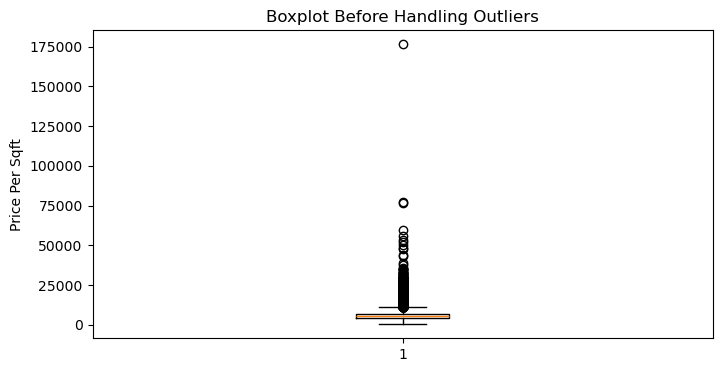

Lower Limit: 139.91153952269178
Upper Limit: 11097.871258104567
After handling outliers:
count    11810.000000
mean      5922.697596
std       2312.413120
min        267.829813
25%       4249.146434
50%       5339.785954
75%       6988.636364
max      11097.871258
Name: price_per_sqft, dtype: float64


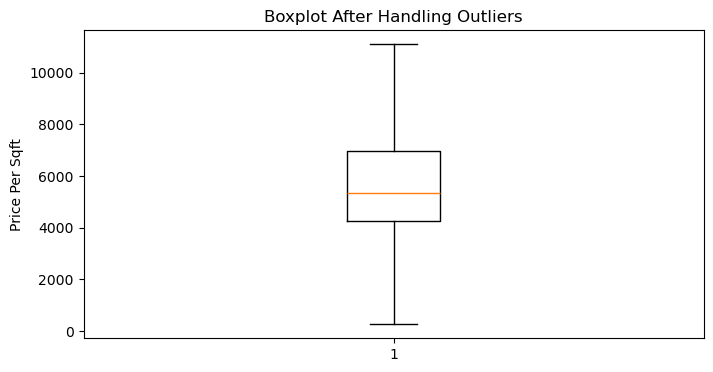

In [27]:
# YOUR CODE HERE
print("Before handling outliers:")
print(df['price_per_sqft'].describe())
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(df['price_per_sqft'].dropna())
plt.title("Boxplot Before Handling Outliers")
plt.ylabel("Price Per Sqft")
plt.show()
Q1 = df['price_per_sqft'].quantile(0.25)
Q3 = df['price_per_sqft'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Limit:", lower)
print("Upper Limit:", upper)
df['price_per_sqft'] = df['price_per_sqft'].clip(lower, upper)
print("After handling outliers:")
print(df['price_per_sqft'].describe())
plt.figure(figsize=(8, 4))
plt.boxplot(df['price_per_sqft'].dropna())
plt.title("Boxplot After Handling Outliers")
plt.ylabel("Price Per Sqft")
plt.show()

**Your answer / justification:**
selected the clipping method because it controls extreme values without deleting records. This helps improve data quality while preserving the dataset size.

---
## Part H: Encoding and scaling

**H1.** One-hot encode `area_type` using `pd.get_dummies`. Show the new columns.

In [28]:
# YOUR CODE HERE
df = pd.get_dummies(df, columns=['area_type'])
print(df.columns)
print(df.filter(like='area_type_').head())


Index(['availability', 'location', 'size', 'total_sqft', 'bath', 'balcony',
       'price', 'bhk', 'price_per_sqft', 'sqft_per_bhk', 'price_band',
       'z_score', 'area_type_Built-up  Area', 'area_type_Carpet  Area',
       'area_type_Plot  Area', 'area_type_Super built-up  Area'],
      dtype='object')
   area_type_Built-up  Area  area_type_Carpet  Area  area_type_Plot  Area  \
0                     False                   False                 False   
1                     False                   False                  True   
2                      True                   False                 False   
3                     False                   False                 False   
4                     False                   False                 False   

   area_type_Super built-up  Area  
0                            True  
1                           False  
2                           False  
3                            True  
4                            True  


**H2.** `location` has too many unique values to one-hot encode directly.
Keep the 10 most frequent locations, replace all others with `"Other"`, then one-hot encode. Explain why this is needed.

In [29]:
# YOUR CODE HERE
top_10 = df['location'].value_counts().head(10).index

print(top_10)
df['location'] = df['location'].where(df['location'].isin(top_10), 'Other')
df = pd.get_dummies(df, columns=['location'])
print(df.filter(like='location_').head())
print(df.filter(like='location_').sum())

Index(['Whitefield', 'Sarjapur Road', 'Electronic City', 'Kanakpura Road',
       'Thanisandra', 'Yelahanka', 'Marathahalli', 'Raja Rajeshwari Nagar',
       'Hebbal', 'Uttarahalli'],
      dtype='object', name='location')
   location_Electronic City  location_Hebbal  location_Kanakpura Road  \
0                     False            False                    False   
1                     False            False                    False   
2                     False            False                    False   
3                     False            False                    False   
4                     False            False                    False   

   location_Marathahalli  location_Other  location_Raja Rajeshwari Nagar  \
0                  False            True                           False   
1                  False            True                           False   
2                  False           False                           False   
3                  False          

**Your answer / justification:**

We use this method to reduce the number of features, save memory and avoid unnecessary columns.

**H3.** Scale `total_sqft` with **min-max scaling** and `bath` with **standardization (z-score)**. Use the formulas directly. Show `describe()` of the scaled columns and confirm that min-max gives a range of 0 to 1 and standardization gives mean about 0 and std about 1.

In [30]:
# YOUR CODE HERE
min_val = df['total_sqft'].min()
max_val = df['total_sqft'].max()

df['total_sqft_scaled'] = (
    (df['total_sqft'] - min_val) / (max_val - min_val)
)
mean = df['bath'].mean()
std = df['bath'].std()

df['bath_scaled'] = (df['bath'] - mean) / std
print("Min-Max Scaled total_sqft:")
print(df['total_sqft_scaled'].describe())

print("\nStandardized bath:")
print(df['bath_scaled'].describe())
print("Min-Max Minimum:", df['total_sqft_scaled'].min())
print("Min-Max Maximum:", df['total_sqft_scaled'].max())

print("Standardization Mean:", df['bath_scaled'].mean())
print("Standardization Std:", df['bath_scaled'].std())


Min-Max Scaled total_sqft:
count    11810.000000
mean         0.025051
std          0.024723
min          0.000000
25%          0.015778
50%          0.019337
75%          0.027130
max          1.000000
Name: total_sqft_scaled, dtype: float64

Standardized bath:
count      11810.0
mean           0.0
std            1.0
min      -1.450802
25%      -0.529076
50%      -0.529076
75%       0.392651
max      12.375093
Name: bath_scaled, dtype: Float64
Min-Max Minimum: 0.0
Min-Max Maximum: 1.0
Standardization Mean: 8.543358888902136e-17
Standardization Std: 1.0


---
## Part I: Insights

**I1.** Find the 10 most expensive localities by **median** `price_per_sqft`, but only consider localities with at least 10 listings. Explain why median and a minimum count are used.

In [34]:
location_cols = [col for col in df.columns if col.startswith('location_')]

location_prices = {}

for col in location_cols:
    median = df.loc[df[col] == 1, 'price_per_sqft'].median()
    location_prices[col.replace('location_', '')] = median

top_10_expensive = pd.Series(location_prices).sort_values(ascending=False).head(10)

print(top_10_expensive)

Hebbal                   7175.685693
Thanisandra              5888.650964
Sarjapur Road            5756.578947
Whitefield               5650.605124
Marathahalli             5500.000000
Other                    5392.156863
Kanakpura Road           5078.081952
Yelahanka                5051.079137
Electronic City          4584.040747
Raja Rajeshwari Nagar    4235.114172
dtype: float64


**Your answer / justification:**
- Median: Used because it is less affected by extremely high or low prices.
- Minimum 10 listings: Ensures a fair and more reliable comparison between localities.

**I2.** Compare the average `price_per_sqft` across `area_type` using a bar chart.

Built-up  Area          5695.555189
Carpet  Area            6380.899893
Plot  Area              8426.750927
Super built-up  Area    5565.389174
dtype: float64


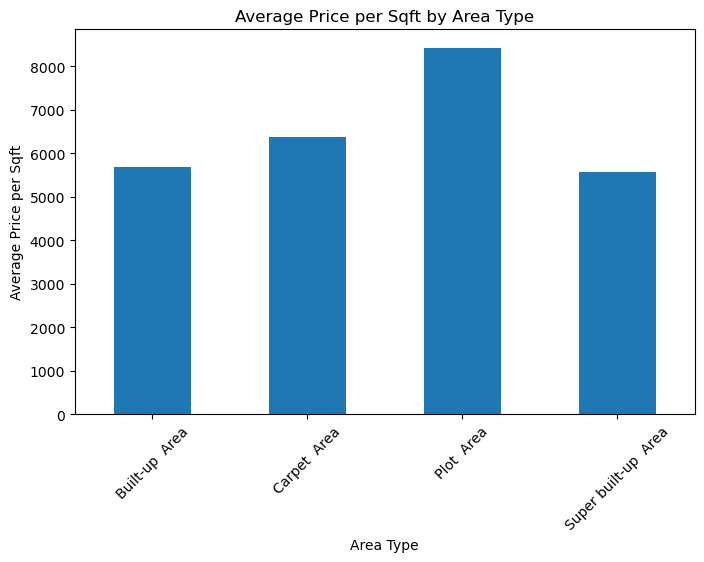

In [35]:
import matplotlib.pyplot as plt

area_cols = [col for col in df.columns if col.startswith('area_type_')]

avg_price = {}

for col in area_cols:
    avg_price[col.replace('area_type_', '')] = df.loc[df[col] == 1, 'price_per_sqft'].mean()

avg_price = pd.Series(avg_price)

print(avg_price)

avg_price.plot(kind='bar', figsize=(8, 5))

plt.title('Average Price per Sqft by Area Type')
plt.xlabel('Area Type')
plt.ylabel('Average Price per Sqft')
plt.xticks(rotation=45)
plt.show()

**I3.** Write 3 recommendations for a first-time home buyer with a budget of your choice, based on your analysis. Mention at least one number from your results in each.

**Your answer / justification:**
Choose affordable localities with lower median price per sqft.
Select the area type with the lowest average price per sqft.
Prefer a 2 BHK flat around 1,000 sqft for comfortable living.

---
## Before you submit

- [ ] Notebook runs from top to bottom without errors
- [ ] Every cleaning decision has a written reason
- [ ] No hard-coded answers (use code, not numbers typed by hand)
- [ ] File is named `RollNo_Name_Bengaluru.ipynb`

**Optional extra:** Add one more insight of your own (for example, the effect of `balcony` or `availability` on price) with a chart and a two-line explanation.